# Oxford IIIT Pets Segmentation using PyTorch

In this notebook, we shall see how to create a SegNet-Basic model to perform image segmentation on the Oxford IIIT Pets dataset.
This dataset can be found [here](https://www.robots.ox.ac.uk/~vgg/data/pets/).

First, we'll create a SegNet Basic model with ~15.27M parameters and record the model's accuracy using multiple metrics:
1. Pixel Accuracy
2. IoU (using torchmetrics)
3. A custom IoU metric we define that is differentiable so that it can be used as a loss function if needed.

Then, we'll use Depthwise Separable Convolutions to reduce the number of parameters in this model from ~15.27M to ~1.75M and record the accuracy of this model on the test dataset using the same set of metrics as above.

Both models are trained for **20 epochs** on the same training dataset. We use random horizontal image flips and color jitter as data augmentation for the training dataset when training both models.

We see that using the depthwise separable convolutions reduces the number of model parameters by about 88% with a very small overall loss in pixel classification accuracy (i.e. the pixel classification accuracy goes from 88.39% to 87.31%).

Here are the detailed results.

| Model | Parameters (in millions) | Pixel Accuracy % | IoU Accuracy % | Custom IoU Accuracy % |
| -------- | ------- | -------- | ------- | -------- |
| SegNet-Basic With Standard Convolutions            | 15.27M | 88.39% | 72.91% | 59.93% |
| SegNet-Basic With Depthwise Separable Convolutions | 1.75M  | 87.31% | 70.49% | 63.04% |


### Imports and helper functions

In [2]:
import torch
from torch import nn
import os
from os import path
import torchvision
import torchvision.transforms as T
from typing import Sequence
from torchvision.transforms import functional as F
import numbers
import random
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt
import torchmetrics as TM
from torch.utils.data import Dataset, random_split
from resource.branch_dataset.dataset import BranchData

# Convert a pytorch tensor into a PIL image
t2img = T.ToPILImage()
# Convert a PIL image into a pytorch tensor
img2t = T.ToTensor()

# Fetch the Oxford IIIT Pets dataset (via Torchvision)

In [38]:
# Oxford IIIT Pets Segmentation dataset loaded via torchvision.
# dataset = BranchData(os.path.join("resource", "branch_dataset"))


In [39]:
# (train_input, train_target) = dataset[0]

In [ ]:
# Spot check an input image.
# t2img(train_input)

In [ ]:
dataset = BranchData(
    os.path.join("resource", "branch_dataset"), 
    transform = T.Compose([
        T.Resize((128, 128), interpolation=T.InterpolationMode.NEAREST)
    ])
)
train_set, test_set = random_split(dataset, [0.9, 0.1])

train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=64,
    shuffle=True,
    num_workers=4
)

test_loader = torch.utils.data.DataLoader(
    test_set,
    batch_size=64,
    shuffle=True,
    num_workers=4
)

## Spot check input images and segmentation masks

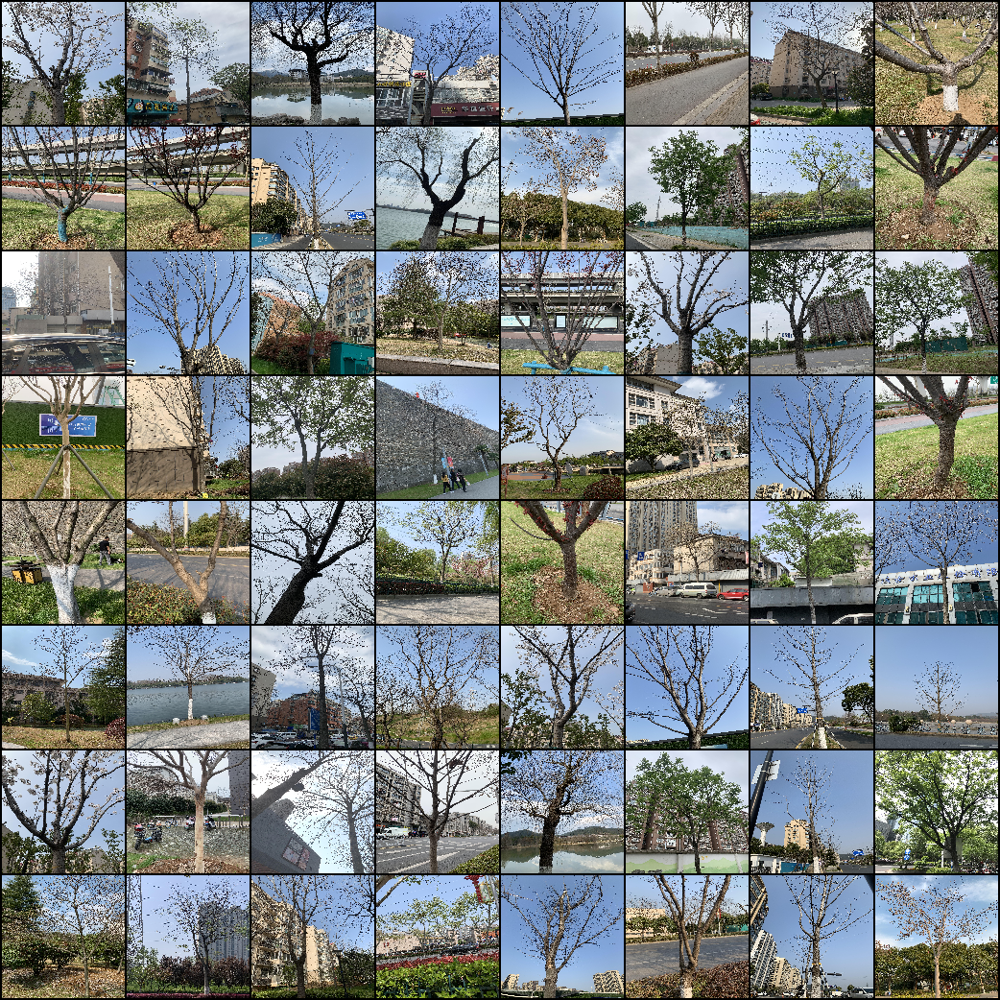

In [20]:
# Let's inspect some of the images.
(batch_in, batch_out) = next(iter(train_loader))
input_grid = torchvision.utils.make_grid(batch_in, nrow=8)
t2img(input_grid)

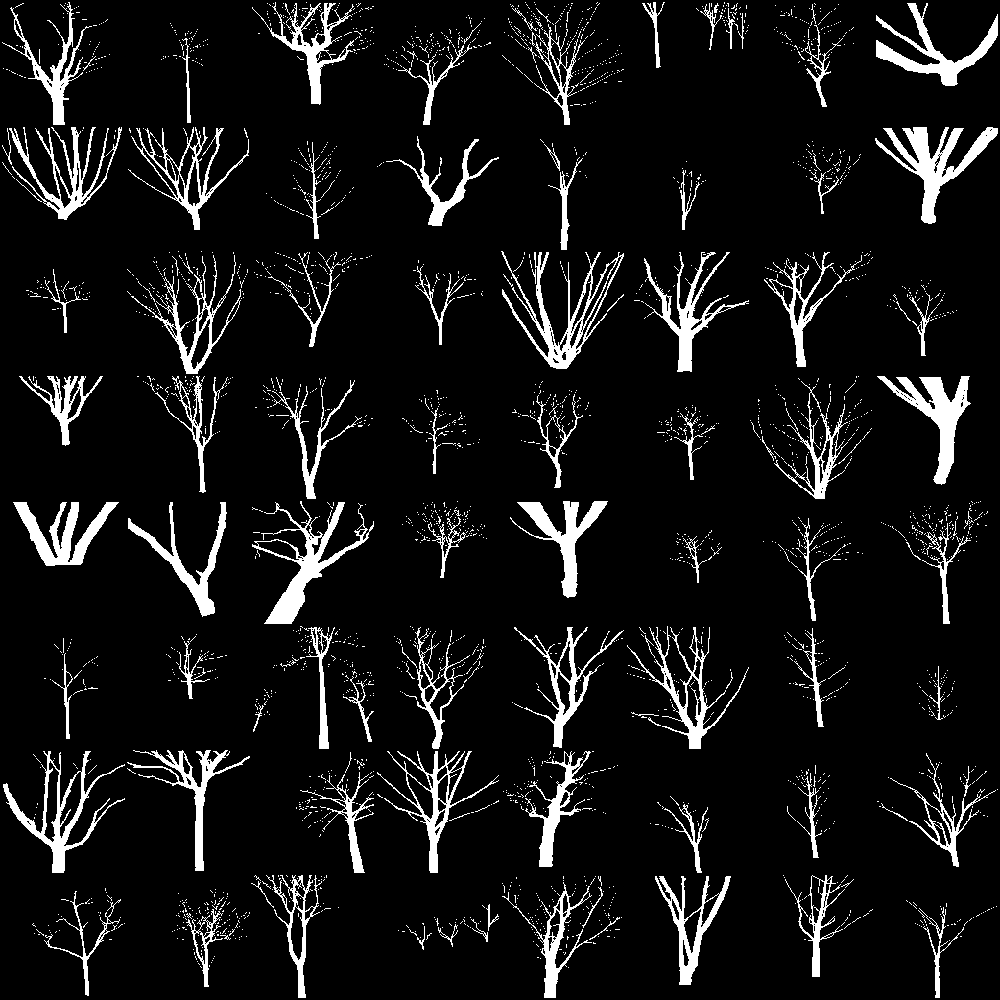

In [21]:
output_grid = torchvision.utils.make_grid(batch_out, nrow=8)
t2img(output_grid*255)

# SegNet Basic with standard convolutions

## Model definition (SegNet Basic)

We use a SegNet model architecture, since it's well suited for image segmentation tasks, and isn't as memory intensive as U-Net models are. More information about the SegNet model and its architecture can be found here: https://arxiv.org/abs/1511.00561

We specifically use a SegNet-Basic type of model (i.e. not very deep) since our input images are just 128x128 in dimension.


In [3]:
# Model definition. We use a SegNet-Basic model with some minor tweaks.
# Our input images are 128x128.
class DownConv2(nn.Module):
    def __init__(self, chin, chout, kernel_size):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_channels=chin, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
            nn.Conv2d(in_channels=chout, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
        )
        self.mp = nn.MaxPool2d(kernel_size=2, return_indices=True)
        
    def forward(self, x):
        y = self.seq(x)
        pool_shape = y.shape
        y, indices = self.mp(y)
        return y, indices, pool_shape

class DownConv3(nn.Module):
    def __init__(self, chin, chout, kernel_size):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_channels=chin, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
            nn.Conv2d(in_channels=chout, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
            nn.Conv2d(in_channels=chout, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
        )
        self.mp = nn.MaxPool2d(kernel_size=2, return_indices=True)
        
    def forward(self, x):
        y = self.seq(x)
        pool_shape = y.shape
        y, indices = self.mp(y)
        return y, indices, pool_shape

class UpConv2(nn.Module):
    def __init__(self, chin, chout, kernel_size):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_channels=chin, out_channels=chin, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chin),
            nn.ReLU(),
            nn.Conv2d(in_channels=chin, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
        )
        self.mup = nn.MaxUnpool2d(kernel_size=2)
        
    def forward(self, x, indices, output_size):
        y = self.mup(x, indices, output_size=output_size)
        y = self.seq(y)
        return y

class UpConv3(nn.Module):
    def __init__(self, chin, chout, kernel_size):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_channels=chin, out_channels=chin, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chin),
            nn.ReLU(),
            nn.Conv2d(in_channels=chin, out_channels=chin, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chin),
            nn.ReLU(),
            nn.Conv2d(in_channels=chin, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.ReLU(),
        )
        self.mup = nn.MaxUnpool2d(kernel_size=2)
        
    def forward(self, x, indices, output_size):
        y = self.mup(x, indices, output_size=output_size)
        y = self.seq(y)
        return y

class UpConv2Final(nn.Module):
    def __init__(self, chin, chout, kernel_size):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_channels=chin, out_channels=chin, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chin),
            nn.ReLU(),
            nn.Conv2d(in_channels=chin, out_channels=chout, kernel_size=kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(chout),
            nn.Sigmoid(),
        )
        self.mup = nn.MaxUnpool2d(kernel_size=2)
        
    def forward(self, x, indices, output_size):
        y = self.mup(x, indices, output_size=output_size)
        y = self.seq(y)
        return y

class ImageSegmentation(torch.nn.Module):
    def __init__(self, kernel_size):
        super().__init__()
        self.out_channels = 1
        self.bn_input = nn.BatchNorm2d(3)
        self.dc1 = DownConv2(3, 64, kernel_size=kernel_size)
        self.dc2 = DownConv2(64, 128, kernel_size=kernel_size)
        self.dc3 = DownConv3(128, 256, kernel_size=kernel_size)
        # self.dc4 = DownConv3(256, 512, kernel_size=kernel_size)
        # self.dc5 = DownConv3(512, 512, kernel_size=kernel_size)
        
        # self.uc5 = UpConv3(512, 512, kernel_size=kernel_size)
        # self.uc4 = UpConv3(512, 256, kernel_size=kernel_size)
        self.uc3 = UpConv3(256, 128, kernel_size=kernel_size)
        self.uc2 = UpConv2(128, 64, kernel_size=kernel_size)
        self.uc1 = UpConv2Final(64, 1, kernel_size=kernel_size)
        
    def forward(self, batch: torch.Tensor):
        x = self.bn_input(batch)
        # x = batch
        # SegNet Encoder
        x, mp1_indices, shape1 = self.dc1(x)
        x, mp2_indices, shape2 = self.dc2(x)
        x, mp3_indices, shape3 = self.dc3(x)
        # x, mp4_indices, shape4 = self.dc4(x)
        # Our images are 128x128 in dimension. If we run 4 max pooling
        # operations, we are down to 128/16 = 8x8 activations. If we
        # do another down convolution, we'll be at 4x4 and at that point
        # in time, we may lose too much spatial information as a result
        # of the MaxPooling operation, so we stop at 4 down conv
        # operations.
        # x, mp5_indices, shape5 = self.dc5(x)

        # SegNet Decoder
        # x = self.uc5(x, mp5_indices, output_size=shape5)
        # x = self.uc4(x, mp4_indices, output_size=shape4)
        x = self.uc3(x, mp3_indices, output_size=shape3)
        x = self.uc2(x, mp2_indices, output_size=shape2)
        x = self.uc1(x, mp1_indices, output_size=shape1)
        
        return x
    # end def
# end class

In [ ]:
# Run the model once on a single input batch to make sure that the model
# runs as expected and returns a tensor with the expected shape.
m = ImageSegmentation(kernel_size=3)
m.eval()
# m(batch_in.float()).shape

## Loss function (Custom IoU and Custom IoU Loss)

We define a custom IoU metric that is differentiable so that it can be used as a loss functions if needed.

This IoU metric is different from the standard IoU metric that has a hard distinction between predicted classes by the model. In this custom IoU metric, we use the probability of the predicted class (after applying SoftMax) to determine the degree of overlap. In that sense, this isn't a pure IoU metric, but it does help us capture the essense of an IoU metric.

IoU is also sometimes called Jaccard Index or Jaccard similarity metric.


### Why use IoU instead of pixel accuracy?

For segmentation tasks, if you have input images where (say) just 10% of the image has the object you wish to cover with the object segmentation mask, and the rest of the image is supposed to be classified as background, then the pixel accuracy metric may not be the best metric to use.

Here's why. If the model were to predict every pixel as a background pixel, it would trivially achieve 90% accuracy for its prediction!

Hence, for cases where the object and background pixels are unbalanced, an IoU metric may be a better choice.

Here are some links to learn more about metrics for segmentation tasks:
1. https://www.kaggle.com/code/yassinealouini/all-the-segmentation-metrics
2. https://towardsdatascience.com/how-accurate-is-image-segmentation-dd448f896388
3. https://towardsdatascience.com/evaluating-image-segmentation-models-1e9bb89a001b


In [24]:
# Define a custom IoU Metric for validating the model.
def IoUMetric(pred, gt, softmax=False):
    # # Run softmax if input is logits.
    # if softmax is True:
    #     pred = nn.Softmax(dim=1)(pred)
    # # end if
    
    # # Add the one-hot encoded masks for all 3 output channels
    # # (for all the classes) to a tensor named 'gt' (ground truth).
    # gt = torch.cat([ (gt == i) for i in range(3) ], dim=1)
    # # print(f"[2] Pred shape: {pred.shape}, gt shape: {gt.shape}")

    intersection = gt * pred
    union = gt + pred - intersection

    # Compute the sum over all the dimensions except for the batch dimension.
    iou = (intersection.sum(dim=(1, 2, 3)) + 0.001) / (union.sum(dim=(1, 2, 3)) + 0.001)
    
    # Compute the mean over the batch dimension.
    return iou.mean()

class IoULoss(nn.Module):
    def __init__(self, softmax=False):
        super().__init__()
        self.softmax = softmax
    
    # pred => Predictions (logits, B, 3, H, W)
    # gt => Ground Truth Labales (B, 1, H, W)
    def forward(self, pred, gt):
        # return 1.0 - IoUMetric(pred, gt, self.softmax)
        # Compute the negative log loss for stable training.
        return -(IoUMetric(pred, gt, self.softmax).log())
    # end def
# end class

def test_custom_iou_loss():
    #               B, C, H, W
    x = torch.rand((2, 3, 2, 2), requires_grad=True)
    y = torch.randint(0, 3, (2, 1, 2, 2), dtype=torch.long)
    z = IoULoss(softmax=True)(x, y)
    return z
# end def

test_custom_iou_loss()

tensor(0.9675, grad_fn=<NegBackward0>)

## Model Training

In [4]:
# Train the model for a single epoch
def train_model(model, loader, optimizer):
    model.train() # Activate "training mode"
    criterion = torch.nn.BCELoss()
    # end if

    running_loss = 0.0
    running_samples = 0
    
    for batch_idx, (inputs, targets) in enumerate(loader, 0):
        optimizer.zero_grad()
        outputs = model(inputs.float())
        
        loss = criterion(outputs.float(), targets.float())
        loss.backward()
        optimizer.step()
    
        running_samples += targets.size(0)
        running_loss += loss.item()
    # end for

    print("Trained {} samples, Loss: {:.4f}".format(
        running_samples,
        running_loss / (batch_idx+1),
    ))

    return running_loss / (batch_idx+1)
# end def


In [5]:
def test_model(model, loader):
    model.eval()
    custom_iou_accuracies = []
    
    for batch_idx, (inputs, targets) in enumerate(loader, 0):
        predictions = model(inputs.float())
        custom_iou = 1.0 - torch.nn.BCELoss()(predictions.float(), targets.float()).item()
        custom_iou_accuracies.append(custom_iou)
        
    return custom_iou_accuracies

## Helpers for validation of results on the test dataset

In [10]:
# Optimizer and Learning Rate Scheduler.
optimizer = torch.optim.Adam(m.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.7)

NameError: name 'm' is not defined

In [ ]:
train_model(m, train_loader, optimizer)

In [31]:
print(test_model(m, test_loader))

[0.4127069115638733, 0.4031640887260437, 0.39568328857421875]


In [32]:
# Define training loop. This will train the model for multiple epochs.
#
# epochs: A tuple containing the start epoch (inclusive) and end epoch (exclusive).
#         The model is trained for [epoch[0] .. epoch[1]) epochs.
#
def train_loop(model, train_loader, test_loader, epochs, optimizer, scheduler):
    epoch_i, epoch_j = epochs
    loss = []
    for i in range(epoch_i, epoch_j):
        epoch = i
        print(f"Epoch: {i:02d}, Learning Rate: {optimizer.param_groups[0]['lr']}")
        train_loss = train_model(model, train_loader, optimizer)
        # end with

        if scheduler is not None:
            scheduler.step()
        # end if

        test_acc = np.mean(test_model(model, test_loader))
        loss.append((train_loss, test_acc))
        print(f"Test set accurracy: {test_acc}")

        print("")

    return loss
    # end for
# end def

In [33]:
# Train our model for 20 epochs, and record the following:
#
# 1. Training Loss
# 2. Test accuracy metrics for a single batch (21 images) of test images. The following
#    metrics are computed:
#   2.1. Pixel Accuracy
#   2.2. IoU Accuracy (weighted)
#   2.3. Custom IoU Accuracy
#
# We also plot the following for each of the 21 images in the validation batch:
# 1. Input image
# 2. Ground truth segmentation mask
# 3. Predicted segmentation mask
#
# so that we can visually inspect the model's progres and determine how well the model
# is doing qualitatively. Note that the validation metrics on the set of 21 images in
# the validation set is displayed inline in the notebook only for the last training
# epoch.
#
losses = train_loop(m, train_loader, test_loader, (2, 22), optimizer, scheduler)

Epoch: 02, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.5739
Test set accurracy: 0.45855842034022015

Epoch: 03, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.5523
Test set accurracy: 0.4746895432472229

Epoch: 04, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.5345
Test set accurracy: 0.47797926266988117

Epoch: 05, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.5210
Test set accurracy: 0.4980590343475342

Epoch: 06, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.5068
Test set accurracy: 0.5008217593034109

Epoch: 07, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.4929
Test set accurracy: 0.5251068671544393

Epoch: 08, Learning Rate: 0.001
Trained 1337 samples, Loss: 0.4839
Test set accurracy: 0.5133827527364095

Epoch: 09, Learning Rate: 0.0007
Trained 1337 samples, Loss: 0.4724
Test set accurracy: 0.5296461482842764

Epoch: 10, Learning Rate: 0.0007
Trained 1337 samples, Loss: 0.4633
Test set accurracy: 0.5385111371676127

Epoch: 11, Learning Rate: 0.0007


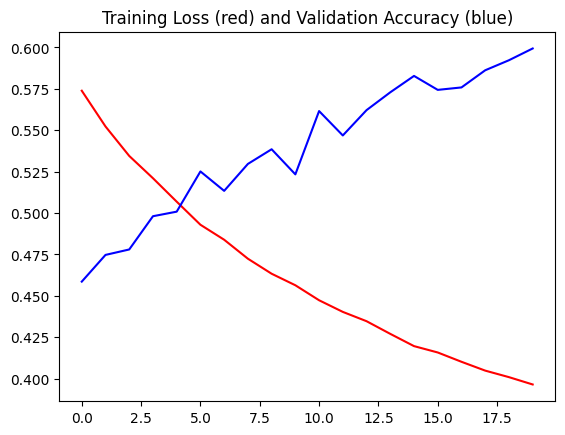

In [34]:
x = range(len(losses))
l = [loss[0] for loss in losses]
a = [loss[1] for loss in losses]

plt.title("Training Loss (red) and Validation Accuracy (blue)")
plt.plot(x, l, 'r-')
plt.plot(x, a, 'b-')
plt.show()

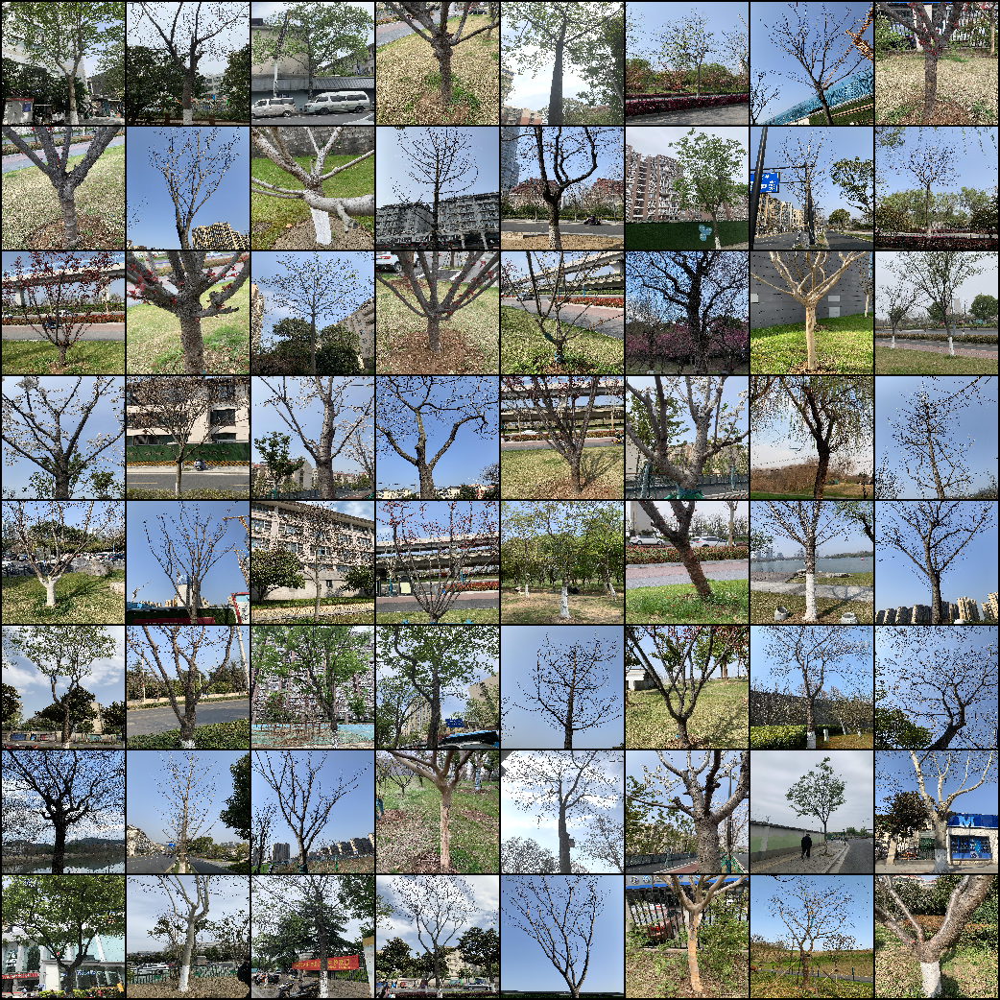

In [35]:
# Let's inspect some of the model output.
(batch_in, batch_out) = next(iter(test_loader))
input_grid = torchvision.utils.make_grid(batch_in, nrow=8)
t2img(input_grid)

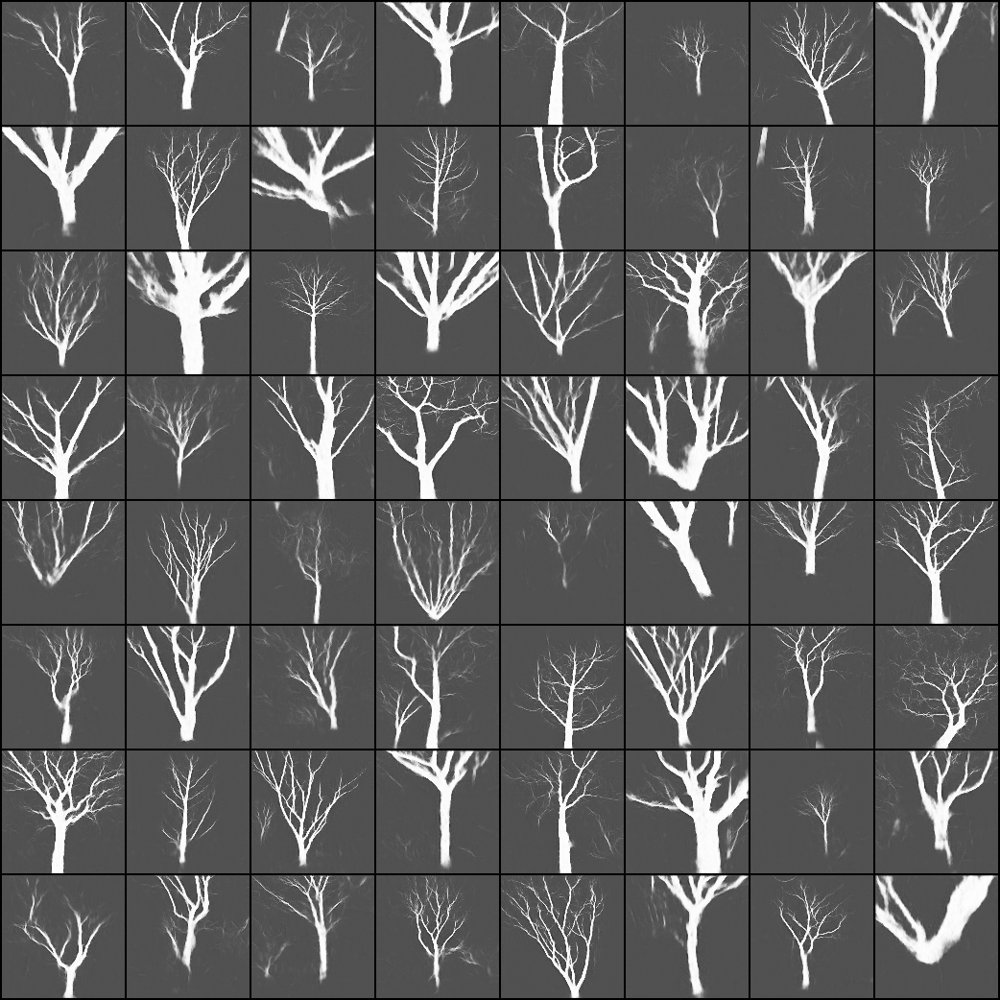

In [36]:
output_grid = torchvision.utils.make_grid(m(batch_in.float()), nrow=8)
t2img(output_grid)

In [37]:
import datetime

torch.save({
    'epoch': 2,
    'model_state_dict': m.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': losses,
    'built_on': datetime.datetime.now(),
}, os.path.join("model_checkpoints", f"checkpoint_nov_14_1chn_out_BCE.tar"))

Augmented Data
==============

In [6]:
from torchvision.io import read_image

class BranchData2(BranchData):
     # defining constructor
    def __init__(self, directory, common_tform=None, input_tform=None):
        super().__init__(directory, common_tform)
        self.input_transform = input_tform
  
    # getting the data items
    def __getitem__(self, idx):
        # defining the image path
        image_name = self.image_names[idx]
        # reading the images
        input = read_image(os.path.join(self.directory, "JPEGImages", f"{image_name}.jpg"))
        output = read_image(os.path.join(self.directory, "SegmentationClass", f"{image_name}.png"))
 
        # apply the transform if not set to None
        if self.transform:
            both = torch.cat([input, output], dim=0)
            both = self.transform(both)
            (input, output) = torch.split(both, 3, dim=0)
        if self.input_transform:
            input = self.input_transform(input)

        output[output != 0] = 1
        
        # returning the image and label
        return input, output

In [7]:
dataset = BranchData2(
    os.path.join("resource", "branch_dataset"), 
    common_tform = T.Compose([
        T.RandomRotation(180),
        T.RandomCrop(1024),
        T.Resize((128, 128), interpolation=T.InterpolationMode.NEAREST),
    ]),
    input_tform = T.Compose([
        T.ColorJitter(brightness=0.3, contrast=0.3),
    ])
)


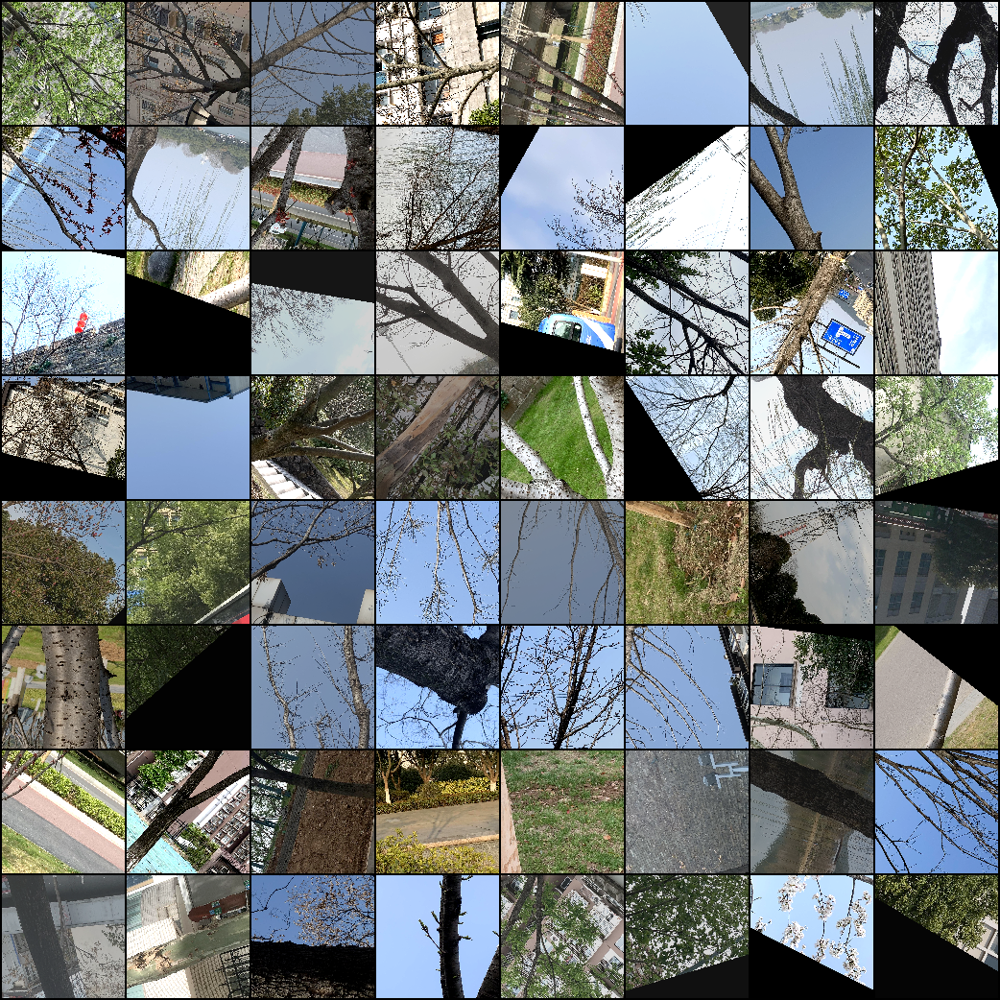

In [8]:
spotcheck = torch.utils.data.DataLoader(
            dataset,
            batch_size=64,
            shuffle=True,
            num_workers=0
        )
(batch_in, batch_out) = next(iter(spotcheck))
input_grid = torchvision.utils.make_grid(batch_in, nrow=8)
t2img(input_grid)

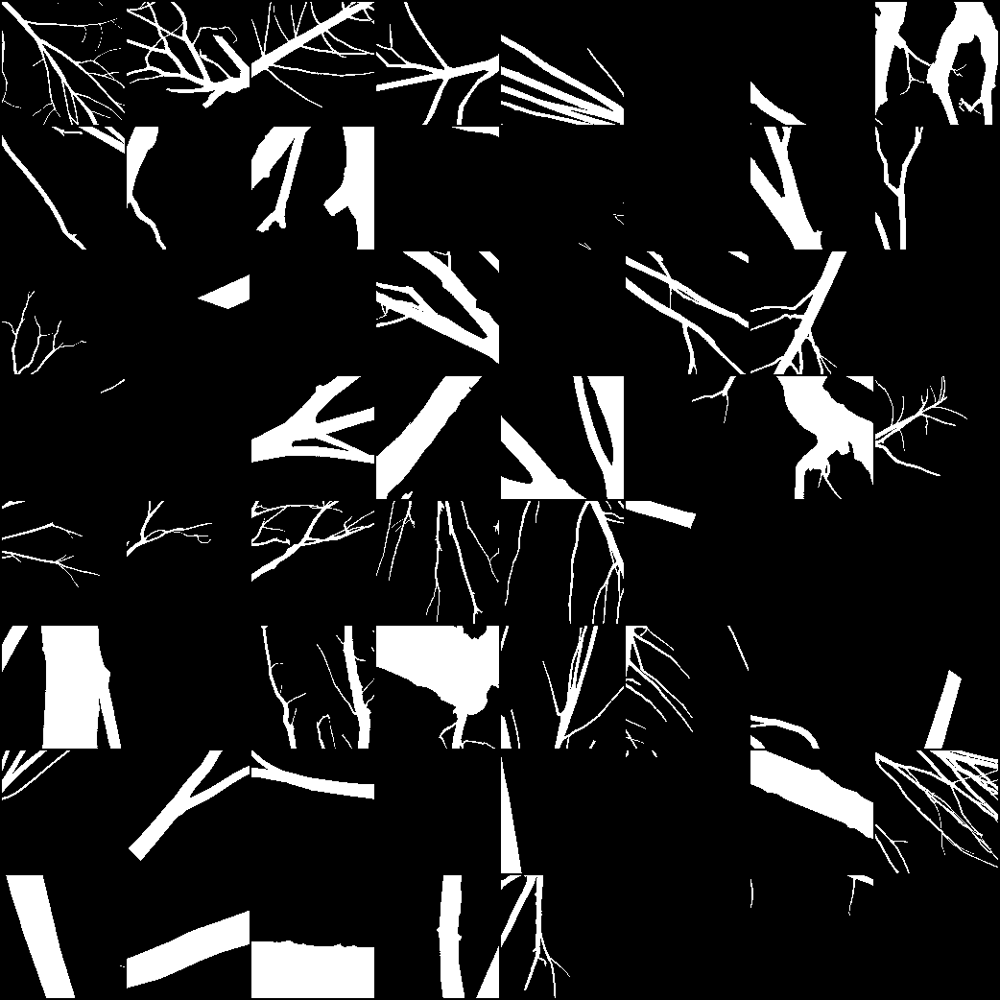

In [9]:
output_grid = torchvision.utils.make_grid(batch_out, nrow=8)
t2img(output_grid*255)

In [16]:
def train_loop_montecarlo(model, dataset, epochs, optimizer, scheduler):
    epoch_i, epoch_j = epochs
    loss = []
    for i in range(epoch_i, epoch_j):
        # Resample test set
        train_set, test_set = random_split(dataset, [0.9, 0.1])

        train_loader = torch.utils.data.DataLoader(
            train_set,
            batch_size=64,
            shuffle=True,
            num_workers=0
        )

        test_loader = torch.utils.data.DataLoader(
            test_set,
            batch_size=64,
            shuffle=True,
            num_workers=0
        )

        # Perform training epoch
        epoch = i
        print(f"Epoch: {i:02d}, Learning Rate: {optimizer.param_groups[0]['lr']}")
        train_loss = train_model(model, train_loader, optimizer)
        # end with

        if scheduler is not None:
            scheduler.step()
        
        # Cross validate
        test_acc = np.mean(test_model(model, test_loader))
        loss.append((train_loss, test_acc))
        print(f"Test set accurracy: {test_acc}")

        print("")

    return loss

In [18]:
checkpoint = torch.load(os.path.join("model_checkpoints", f"checkpoint_nov_14_1chn_out_BCE.tar"))
m = ImageSegmentation(kernel_size=3)
m.load_state_dict(checkpoint["model_state_dict"])
# Optimizer and Learning Rate Scheduler.
optimizer = torch.optim.Adam(m.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.7)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

In [19]:
losses = train_loop_montecarlo(m, dataset, (23, 43), optimizer, scheduler)

Epoch: 23, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.5028
Test set accurracy: -3.935521125793457

Epoch: 24, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4781
Test set accurracy: 0.15581828355789185

Epoch: 25, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4706
Test set accurracy: 0.5941802461942037

Epoch: 26, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4424
Test set accurracy: 0.5840947230656942

Epoch: 27, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4351
Test set accurracy: 0.5830334623654684

Epoch: 28, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4361
Test set accurracy: 0.5041853984196981

Epoch: 29, Learning Rate: 0.00049
Trained 1337 samples, Loss: 0.4334
Test set accurracy: 0.6004790763060252

Epoch: 30, Learning Rate: 0.000343
Trained 1337 samples, Loss: 0.4217
Test set accurracy: 0.5941227972507477

Epoch: 31, Learning Rate: 0.000343
Trained 1337 samples, Loss: 0.4210
Test set accurracy: 0.5990226864814758

Epoch: 32, Learn

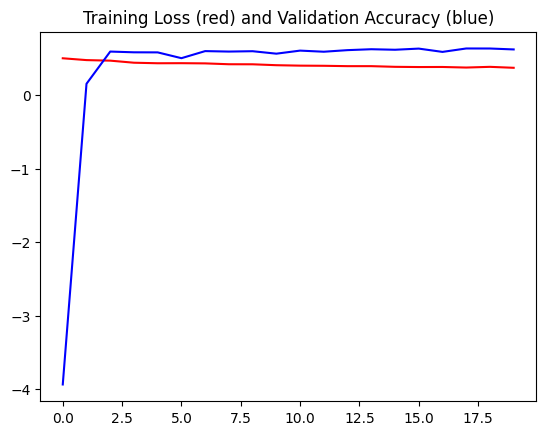

In [20]:
x = range(len(losses))
l = [loss[0] for loss in losses]
a = [loss[1] for loss in losses]

plt.title("Training Loss (red) and Validation Accuracy (blue)")
plt.plot(x, l, 'r-')
plt.plot(x, a, 'b-')
plt.show()

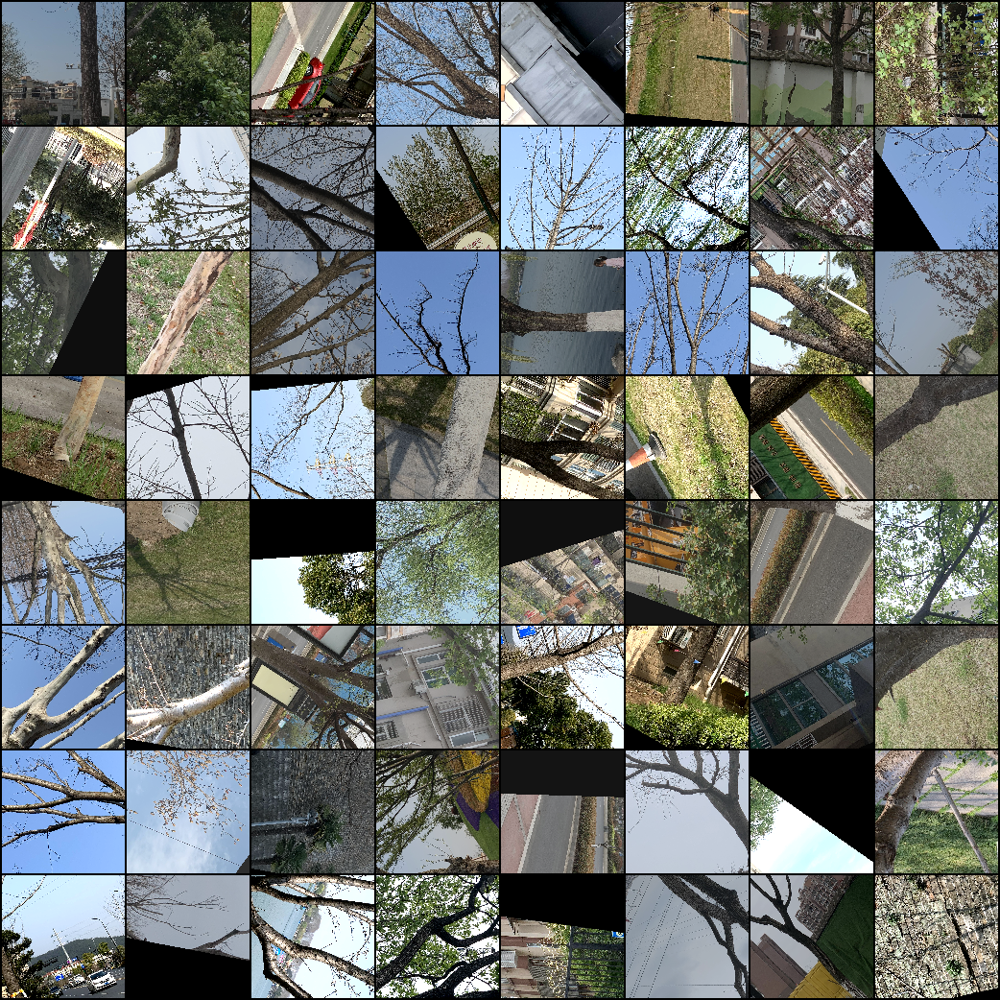

In [26]:
test_loader = torch.utils.data.DataLoader(
            dataset,
            batch_size=64,
            shuffle=True,
            num_workers=0
        )
(batch_in, batch_out) = next(iter(test_loader))
input_grid = torchvision.utils.make_grid(batch_in, nrow=8)
t2img(input_grid)

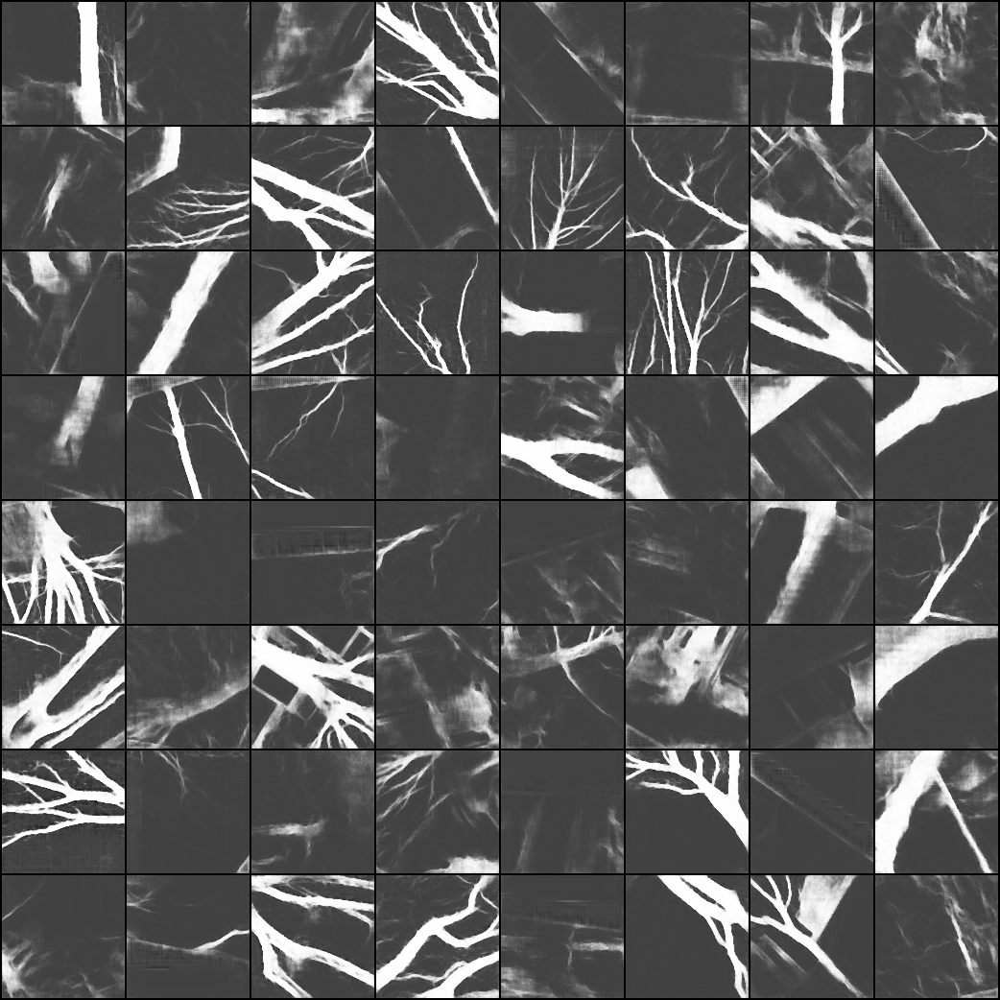

In [27]:
output_grid = torchvision.utils.make_grid(m(batch_in.float()), nrow=8)
t2img(output_grid)

In [25]:
import datetime
torch.save({
    'epoch': 43,
    'model_state_dict': m.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': losses,
    'built_on': datetime.datetime.now(),
}, os.path.join("model_checkpoints", f"checkpoint_nov_15_augmented_data.tar"))

In [28]:
dataset = BranchData(
    os.path.join("resource", "branch_dataset"), 
    transform = T.Compose([
        T.Resize((128, 128), interpolation=T.InterpolationMode.NEAREST)
    ])
)
test_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    shuffle=True,
    num_workers=4
)

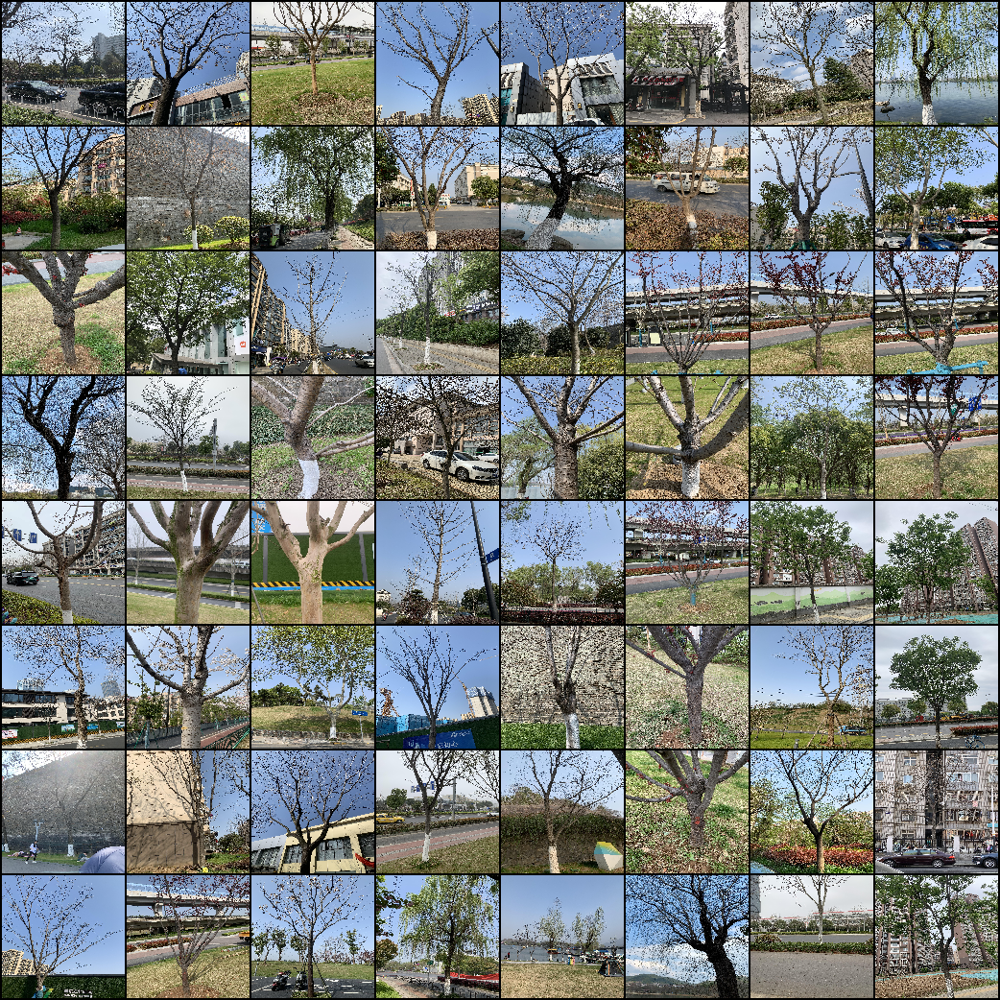

In [29]:
(batch_in, batch_out) = next(iter(test_loader))
input_grid = torchvision.utils.make_grid(batch_in, nrow=8)
t2img(input_grid)

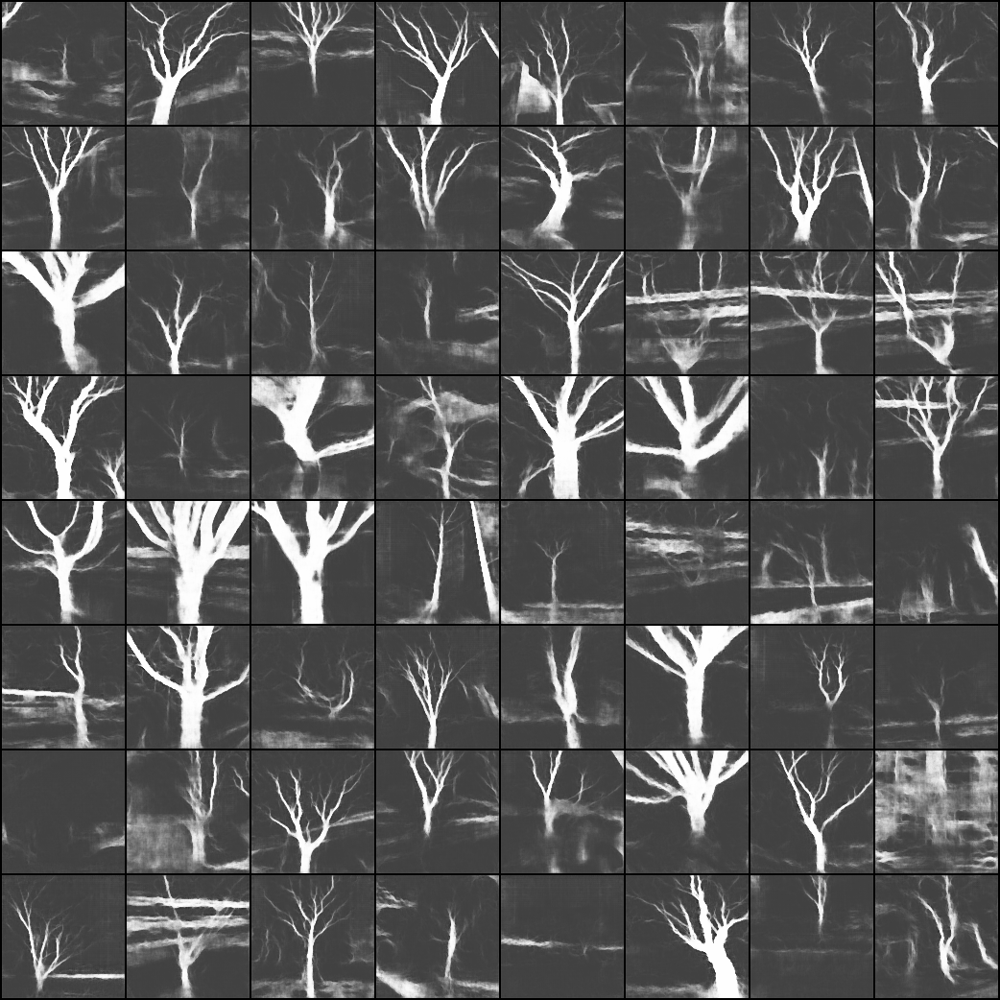

In [30]:
output_grid = torchvision.utils.make_grid(m(batch_in.float()), nrow=8)
t2img(output_grid)

In [ ]:
score = test_model(m, test_loader)
print(np.mean(score))
print(np.std(score))